# CircularMetricsPy
### Developed by Daniel Pert and Ana I. Torres - Carnegie Mellon University
This notebook calculates a company's Circulytics score using ipywidgets. It implements the Ellen MacArthur Foundation's [archived methodology](https://www.circulytics.com/). Note: this tool is unofficial and not affiliated with the Ellen MacArthur Foundation.


In [6]:
import json, numpy as np, pandas as pd
import ipywidgets as w
from ipywidgets import interact_manual, FloatText, VBox, Output, Label
from IPython.display import display, Markdown

from params import *
from utils import *

## We first ask you about your company, to find out how you will be assessed.
### Basic company information: For company identification and statistical analyses
### Run the following code cell to enable data entry. DO NOT run it again (otherwise data will be erased).  The same applies to the other code cells below.

In [35]:
year_label = w.Label(value='0a. Which financial reporting year is the company information provided relevant for?')
year_box = w.IntText(value=2025, disabled=False)
year_container = w.VBox([year_label, year_box])

company_name_label = w.Label(value='0b. Company Name')
company_name_box = w.Text(value='')
company_name = w.VBox([company_name_label, company_name_box])

scope_label = w.Label(value='0c. (Optional) Which scope are you reporting on? ')
scope_box = w.Dropdown(options=['Equity share','Financial control','Operational control','Custom'], description='Scope')
scope = w.VBox([scope_label, scope_box])

customized_scope_label = w.Label(value=' (Optional) If Custom, please describe:')
customized_scope_box = w.Text(value='')
customized_scope = w.VBox([customized_scope_label, customized_scope_box])

revenue_label = w.Label(value='0d. Total revenue from the financial year selected at the beginning of the assessment (in US Dollars)')
revenue_sublabel = w.Label(value='If responding on behalf of a not-for-profit organisation, please use funding spent instead of revenue.')
revenue_box = w.FloatText(value=0.0)
revenue = w.VBox([revenue_label, revenue_sublabel, revenue_box])

employees_label = w.Label(value='0e. Total number of employees')
employees_box = w.IntText(value=0)
employees = w.VBox([employees_label, employees_box])

company_info_box = w.VBox([year_container, company_name, scope, customized_scope, revenue, employees])
company_info_box

# Company Characteristics

- In this section, you will be asked for your industry classification, and whether your company specialises in, for example, product and materials, services, and water. Your responses here determine which Circulytics indicators in the Outcomes category are applicable to your company’s assessment.
- Figure 1 below shows how your responses in this section influence which Circulytics indicators are relevant to your company. A step-by-step explanation is also given along with each question in this section.
- In the Outcomes category, the following indicators are universally relevant, regardless of your company characteristics: 
  - Theme 8. Plant, property, and equipment assets
  - Indicator 10a. Energy Use
- The relevance of the remaining themes and indicators within the Outcomes category (themes 6, 7, 9, and 11, and 10b) depends on responses to the following questions (0f-0l).

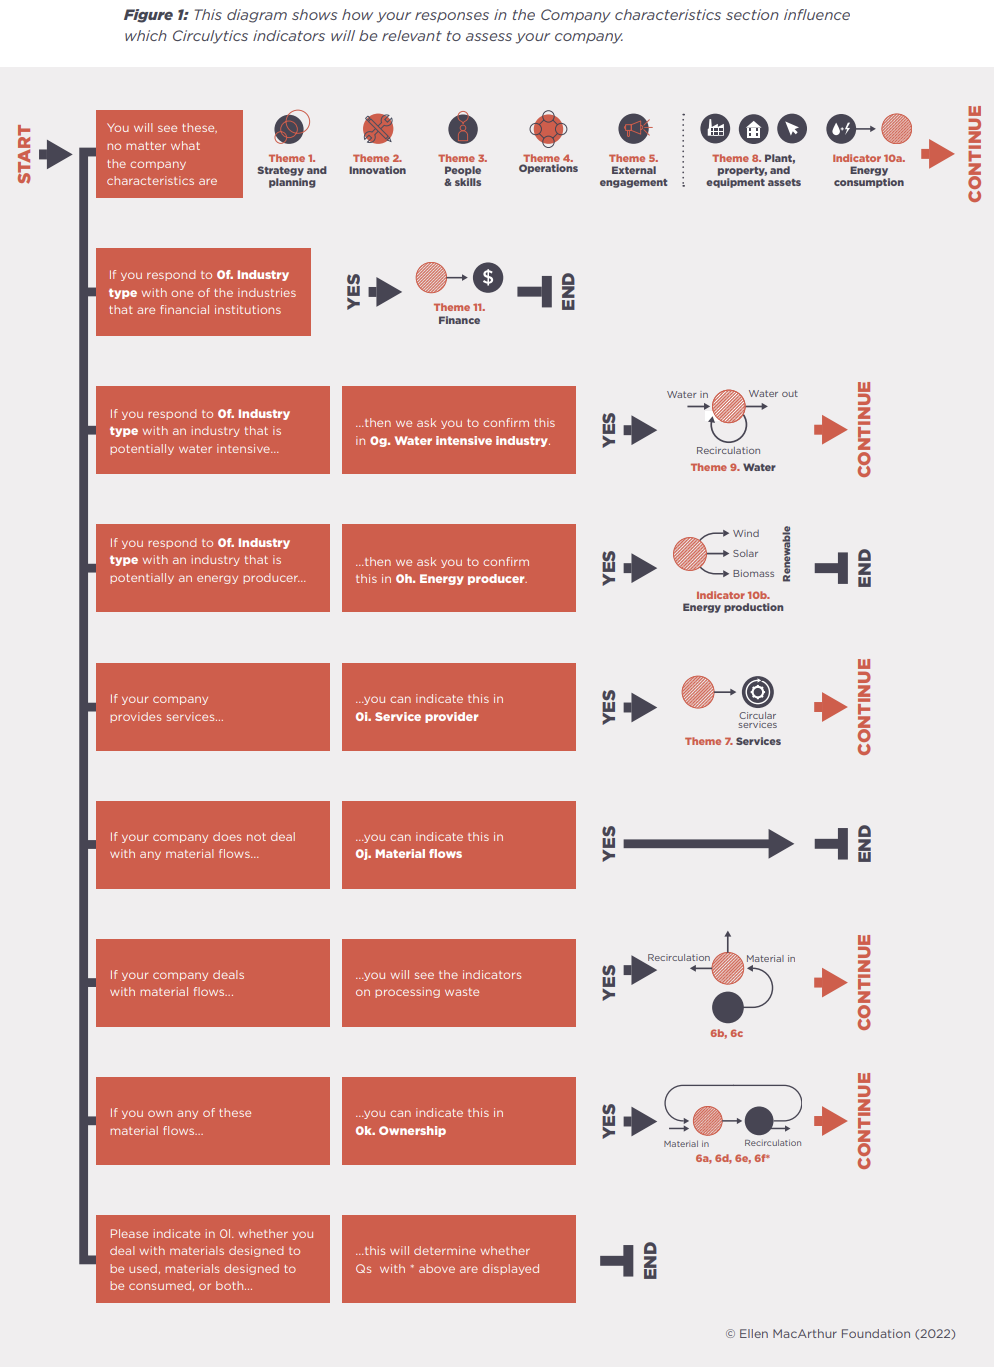

In [41]:
industry_type_label = w.HTML('0f. Primary industry of company')
industry_type_sublabel_1 = w.HTML("""
                                  <div style="margin-left: 40px;">
                                  If unsure, please select the classification that best describes the largest segment of your business practices and provide details in the text box below</div>
                                  """)
industry_type_sublabel_2 = w.HTML("""
                                  <div style="margin-left: 40px;">
                                  If the company industry type is a financial institution in the Circulytics Industry list, THEME 11. FINANCE is relevant, and themes 6, 7, and 9, and indicator 10b are not. Financial institutions should proceed to Information for weighting.
                                  </div>
                                  """)
industry_type = w.Dropdown(options=industry_classes, layout={'width':'500px', 'margin':'0 0 0 40px'}, indent = True)
industry_type_container = w.VBox([industry_type_label, industry_type_sublabel_1, industry_type_sublabel_2, industry_type])

water_intensive = w.Checkbox(value=False, description='0g. Does your company deal with water flows that count as water intensive?', layout=layout, indent=False)
water_intensive_desc_1 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If your company belongs to an industry that is water intensive in our Industry list, this question is used to decide the relevance of THEME 9. WATER
                          </div>
                          """)
water_intensive_desc_2 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          Water intensive refers to companies that use significant volumes of water in their core operations, including but not limited to: cultivation, material processing, (re-)manufacturing, waste management, energy production. Water used in offices is likely to be negligible, and should not be considered as 'water intensive' core operation.
                          </div>
                          """)
energy_producer = w.Checkbox(value=False, description='0h. Does your company produce energy that is sold to customers?', layout=layout, indent=False)

energy_producer_desc_1 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If your company belongs to an industry that is an energy producer in our Industry list, this question is used to decide the relevance of INDICATOR 10b: ENERGY PRODUCTION
                          </div>
                          """)
energy_producer_desc_2 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If 0h. confirms that your company is an energy producer, Themes 6, 7, and 11 are not relevant and you can proceed to Information for weighting.
                                </div>
                          """)

services_sold = w.Checkbox(value=False, description='0i. Does your company sell services?', layout=layout, indent=False)
services_sold_desc_1 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If responding on behalf of a not-for-profit organization, please use funding spent on services instead of services sold.
                          </div>
                          """)
services_sold_desc_2 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If the response to 0i. is ‘No’, THEME 6. PRODUCTS AND MATERIALS is relevant but not THEME 7. SERVICES and you can proceed to 0l.
                                </div>
                          """)
services_sold_desc_3 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If the response is ‘Yes’, THEME 7. SERVICES is relevant. What remains to be determined is the extent to which indicators within THEME 6. PRODUCTS AND MATERIALS are relevant for your company
                                </div>
                          """)

material_flows = w.Checkbox(value=True, description='0j. Does your company deal with material flows?', layout=layout, indent=False)
material_flows_desc_1 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                               <ul>
                                <li> Please note that plant, property, and equipment assets used in your company operations (e.g. office buildings and IT equipment) are not within the scope of material flows.
                                <li> Plant, property, and equipment assets owned by your company but used by customers (e.g. reusable pallets in a product as a service business model), are included in the scope of material flows.
                                <li> Services sold by your company that include material flows are included in the scope of material flows.
                                </ul>
                          </div>
                          """)
material_flows_desc_2 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If the response is ‘No’, THEME 6. PRODUCTS AND MATERIALS is not relevant and you can proceed to Information for weighting.
                                </div>
                          """)
text_0k = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          If you reach this point, the responses to both 0i. and 0j. must be ‘Yes’, which means your company sells services and deals with material flows. The relevance of indicators within THEME 6. PRODUCTS AND MATERIALS now depend on the company’s ownership of materials. This step allows you to assess your company more accurately. It allows you to capture the difference between, for example, car leasing companies (that own the cars) and car repair shops (that don’t own the cars)
                                </div>
                          """)
ownership = w.Checkbox(value=False, description="0k. Does your company own any of the material flows you responded 'Yes' to above? For example, car leasing companies own their cars while car repair shops don't own the cars that they deal with.", layout={'width': '1500px'}, indent=False)
ownership_desc_1 = w.HTML(value="""
                          <div style="margin-left: 40px;">
                          <ul>
                            <li> Plant, property, and equipment assets owned by your company but used by customers (e.g. reusable pallets in a product as a service business model), are included in the scope of material flows that your company owns.
                            <li> If the response is ‘Yes’, THEME 6. PRODUCTS AND MATERIALS is relevant and only 0l. remains to be answered.
                            <li> If the response is ‘No’, the implication is that your company only deals with physical products in the context of services (e.g. car repairs) and does not own any of the material flows (e.g. cars going in and out of your repair shop). A reduced version of THEME 6. PRODUCTS AND MATERIALS is relevant, limited to processing waste (e.g. broken car parts that a car repair shop disposes of). Only the indicators 6b. AND/OR 6c. PROCESSING WASTE RECIRCULATION are relevant and only 0l. remains to be answered.
                          </ul>
                          </div>
                          """)

types_of_flows_description1 = w.Label(value='0l. Which of the following statements best describes the types of product and material outflows of your company?')
types_of_flows = w.Dropdown(options=["Products and materials that are designed to be consumed", "Products and materials that are designed to be used", "Both of the above"], layout={'width':'500px'})
types_of_flows_description2 = w.HTML(value="""
<div style="margin-left: 40px;">
                          This decides the relevance of see indicators for (1) products and materials that are designed to be consumed, e.g. food and feed (6b. PROCESSING WASTE RECIRCULATION) and/or indicators for (2) products and materials that are designed to be used (6c. PROCESSING WASTE RECIRCULATION + 6f. PART 1. and 6f. PART 2. PRODUCT RECIRCULATION)
                          </div>
                                     """)
types_of_flows_description_box = w.VBox([types_of_flows_description1, types_of_flows, types_of_flows_description2])

char_box = w.VBox([industry_type_container, water_intensive, water_intensive_desc_1, water_intensive_desc_2, energy_producer, energy_producer_desc_1, energy_producer_desc_2, services_sold, services_sold_desc_1, services_sold_desc_2, services_sold_desc_3, material_flows,material_flows_desc_1,material_flows_desc_2,text_0k, ownership, ownership_desc_1,  types_of_flows_description_box])
char_box

# Information for weighting
### Information used for weighting the Circulytics indicators, also used for statistical analyses.

For more detail about the weighting methodology, see Method Introduction.
You may need to aggregate data from different parts of the company.
- When aggregating data, it should be weighted by the size of the company part it belongs to.
- Note that the size information used to aggregate data is different for the themes. For example, headcount should be used to aggregate data in Theme 3 (People and Skills) and revenue should be used to aggregate Theme 5 (External engagement). The relevant size information is listed next to the theme in the table below.

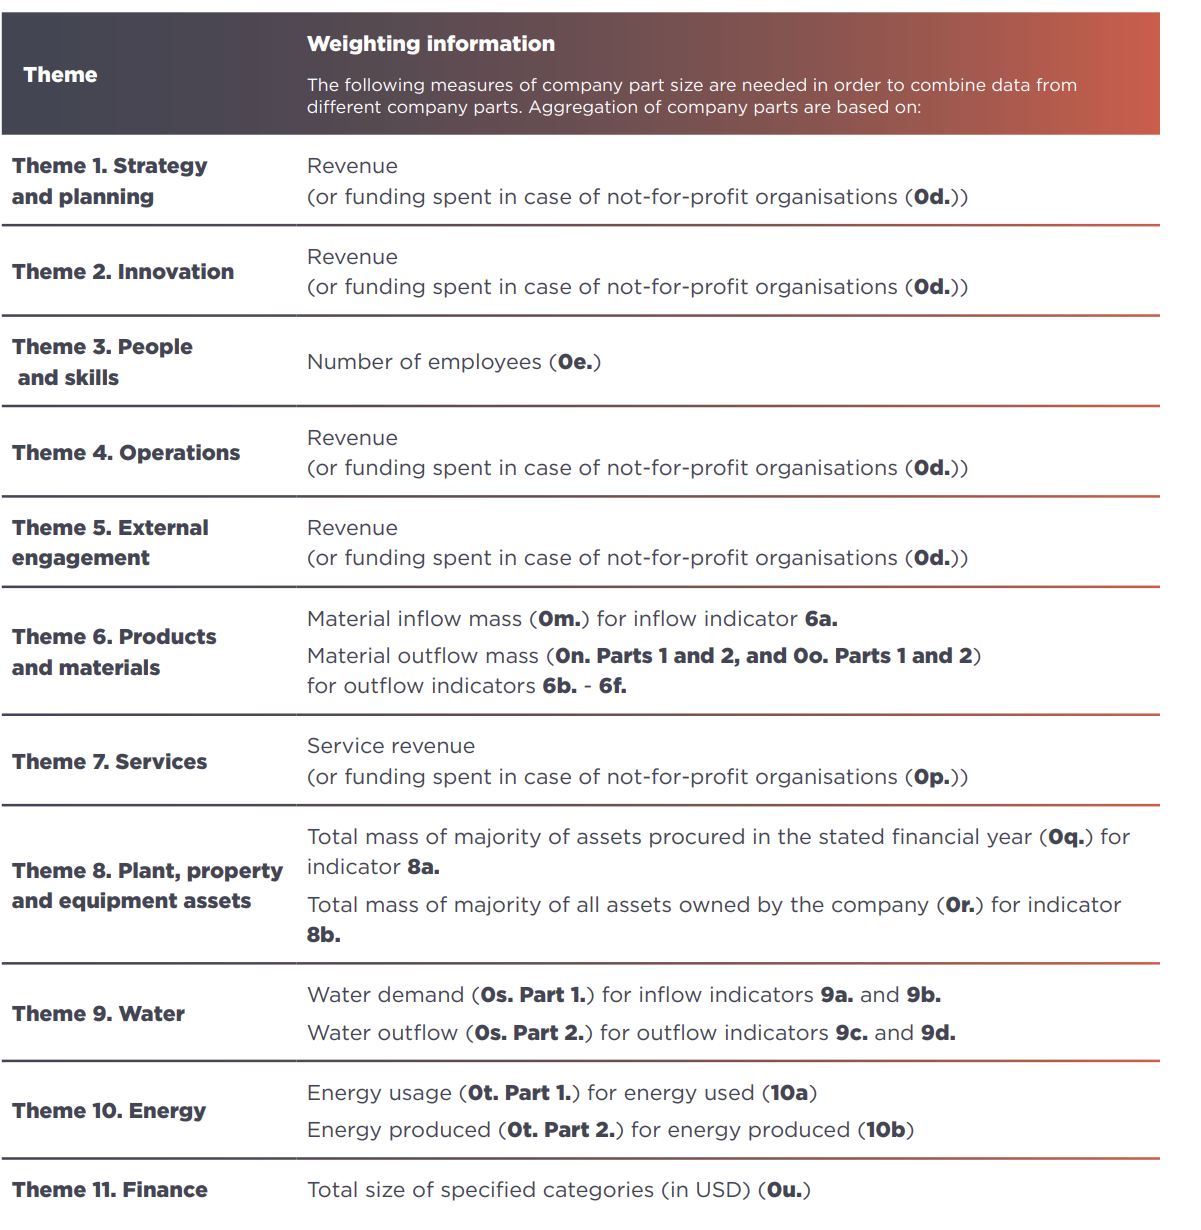

In [42]:
company_info = {'industry_type':industry_type.value,'services_sold':services_sold.value,'material_flows':material_flows.value,'ownership':ownership.value,'water_intensive':water_intensive.value,'energy_producer':energy_producer.value, "types_of_flows":types_of_flows.value}
outcomes_theme_weights = compute_outcomes_theme_weights(company_info)
applicable_outcomes_themes = [theme_num for theme_num, weight in outcomes_theme_weights.items() if weight > 0]

In [43]:
weighting_boxes, M_in, M_prod1, M_prod2, M_waste1, M_waste2, water_demand, water_outflow, energy_use, energy_prod, asset_widgets_procured, asset_widgets_owned, finance_widgets = create_weighting_info_ui(company_info, applicable_outcomes_themes)

In [44]:
for tm in applicable_outcomes_themes:
    display(weighting_boxes[tm])

In [45]:
# Build the UI interfaces to enter the indicators
theme_indicator_ui_boxes, theme_indicator_widgets = create_indicator_ui(company_info,industry_type, finance_widgets, asset_widgets_owned, asset_widgets_procured)

# Information for Circulytics Indicators

In [46]:
for tm in enablers+applicable_outcomes_themes:
    display(theme_indicator_ui_boxes[tm])

In [47]:
compute_btn = w.Button(description='Compute Circulytics score', button_style='success', layout=w.Layout(width='300px'))
report_out = w.Output()

ui = w.VBox([compute_btn, report_out])

def compute_scores(_):
    report_out.clear_output()
    with report_out:
        if 6 in applicable_outcomes_themes:
            masses = {'M_IN':float(M_in.value),'M_PROD1':float(M_prod1.value),'M_PROD2':float(M_prod2.value),'M_WASTE1':float(M_waste1.value),'M_WASTE2':float(M_waste2.value)}
            t6_w = theme6_indicator_weights(company_info, masses, theme_indicator_widgets)

        ind_scores = {tm: {} for tm in enablers + applicable_outcomes_themes}
        theme_scores = {}
        for tm in ind_scores.keys():
            for ind in theme_indicators[tm]:
                if not company_info['energy_producer'] and ind == '10b':
                    continue
                if not company_info['ownership'] and tm == 6 and ind not in ['6b', '6c']:
                    continue
                if company_info["types_of_flows"] == "Products and materials that are designed to be consumed" and tm == 6 and ind in ['6c','6f']:
                    continue
                if company_info["types_of_flows"] == "Products and materials that are designed to be used" and tm == 6 and ind == '6b':
                    continue
                if theme_indicators[tm][ind]['type'] == 'dropdown':
                    value = theme_indicator_widgets[tm][ind]['dropdown'].value
                    if 'bonus_checkbox' in theme_indicator_widgets[tm][ind] and theme_indicator_widgets[tm][ind]['bonus_checkbox'].value:
                        value += theme_indicators[tm][ind]['bonus_checkbox']["score_bonus"]
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'multiple_dropdown':
                    value = theme_indicator_widgets[tm][ind]["get_total_score"]()
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'checkbox':
                    ind_scores[tm][ind] = clip_0_to_1(sum([theme_indicators[tm][ind]['scores'][i] for i, cb in enumerate(theme_indicator_widgets[tm][ind]) if cb.value]))
                elif theme_indicators[tm][ind]['type'] == 'checkbox_table':
                    value = theme_indicator_widgets[tm][ind]['get_score']()
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'both':
                    dd_widget, cb_widgets = theme_indicator_widgets[tm][ind]
                    ind_scores[tm][ind] = clip_0_to_1(dd_widget.value + sum([theme_indicators[tm][ind]['checkbox_scores'][i] for i, cb in enumerate(cb_widgets) if cb.value]))
                elif theme_indicators[tm][ind]['type'] == 'slider':
                    if ind in ['6b','6c']:
                        # for 6b and 6c, a higher score is worse, so the score is one minus the slider value
                        ind_scores[tm][ind] = clip_0_to_1(1 - theme_indicator_widgets[tm][ind].value)
                    else:
                        ind_scores[tm][ind] = clip_0_to_1(theme_indicator_widgets[tm][ind].value)
                elif theme_indicators[tm][ind]['type'] == 'sliders':
                    api = theme_indicator_widgets[tm][ind]
                    ind_scores[tm][ind] = clip_0_to_1(api['get_weighted_score']())
                elif theme_indicators[tm][ind]['type'] == 'float':
                    value = theme_indicator_widgets[tm][ind].value
                    if 'max' in theme_indicators[tm][ind] and theme_indicators[tm][ind]['max'] is None:
                        ind_scores[tm][ind] = max(0, value)
                    else:
                        ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'float_table':
                    api = theme_indicator_widgets[tm][ind]
                    value = api['get_overall_score']()
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif ind == "7a_part2":
                    # 7a part 2 does not have a score
                    continue
                else:
                    print(f"Unknown indicator type for {ind}")
            if tm == 5:
                theme_scores[tm] = weighted_average([(ind_scores[tm][ind], THEME_5_INDICATOR_WEIGHTS[ind]) for ind in ind_scores[tm]])
            elif tm in [1,2,3,4]:
                theme_scores[tm] = float(np.mean([ind_scores[tm][ind] for ind in ind_scores[tm]]))
            elif tm == 6:
                theme_scores[tm] = weighted_average([(ind_scores[tm][ind], t6_w[ind]) for ind in ind_scores[tm]])
            elif tm == 7:
                theme_scores[tm] = ind_scores[tm]['7a_part1']
            elif tm == 8:
                total_asset_mass_procured = sum([wid['mass_widget'].value for wid in asset_widgets_procured])
                total_asset_mass_owned = sum([wid['mass_widget'].value for wid in asset_widgets_owned])
                total_owned_plus_procured = total_asset_mass_owned + total_asset_mass_procured
                if total_owned_plus_procured == 0:
                    theme_scores[tm] = 0.0
                else:
                    theme_scores[tm] = (total_asset_mass_procured/total_owned_plus_procured)*theme_indicator_widgets[8]['8a']['get_overall_score']() + (total_asset_mass_owned/total_owned_plus_procured)*theme_indicator_widgets[tm]['8b']['get_score']()
            elif tm == 9:
                t9_w = theme9_indicator_weights(float(water_demand.value), float(water_outflow.value))
                theme_scores[tm] = sum([ind_scores[tm][ind]*t9_w[ind] for ind in ind_scores[tm]])
            elif tm == 10:
                t10_w = theme10_indicator_weights(float(energy_use.value), float(energy_prod.value), energy_producer.value)
                theme_scores[tm] = sum([ind_scores[tm][ind]*t10_w[ind] for ind in ind_scores[tm]])
            elif tm == 11:
                theme_scores[tm] = np.mean([ind_scores[tm][ind] for ind in ind_scores[tm]])
        
        Enablers_score = weighted_average([(theme_scores[tm], ENABLER_THEME_WEIGHTS[tm]) for tm in [1,2,3,4,5]])
        Outcomes_score = weighted_average([(theme_scores[tm], outcomes_theme_weights[tm]) for tm in applicable_outcomes_themes])
        Overall_equal = (Enablers_score + Outcomes_score) / 2.0
        Overall_score = Outcomes_score if Outcomes_score > Enablers_score else Overall_equal
        Overall_letter = to_letter_score(100*Overall_score)
        display(Markdown('### Results'))
        display(Markdown(f'Enablers score: {100*Enablers_score:.2f}%  '))
        display(Markdown(f'Outcomes score: {100*Outcomes_score:.2f}%  '))
        display(Markdown(f'Overall score: {100*Overall_score:.2f}% -> {Overall_letter}'))
        df_enab = pd.DataFrame({'Theme':[f"Theme {n}: {theme}" for n, theme in theme_names.items() if n in enablers],'Score %':[round(100*theme_scores[tm], 2) for tm in enablers],'Weight %':[round(100*ENABLER_THEME_WEIGHTS[tm], 0) for tm in enablers]})
        df_out = pd.DataFrame({'Theme':[f"Theme {n}: {theme}" for n, theme in theme_names.items() if n in applicable_outcomes_themes],'Score %':[round(100*theme_scores[tm], 2) for tm in applicable_outcomes_themes],'Weight %':[round(100*outcomes_theme_weights[tm], 0) for tm in applicable_outcomes_themes]})
        display(Markdown('#### Enablers'))
        display(df_enab)
        display(Markdown('#### Outcomes'))
        display(df_out)
        result = {'company':company_info,'enablers':{'scores':{tm: theme_scores[tm] for tm in enablers}},'outcomes':{'scores':{tm: theme_scores[tm] for tm in applicable_outcomes_themes},'weights':outcomes_theme_weights},'category_scores':{'Enablers':Enablers_score,'Outcomes':Outcomes_score},'overall':{'score':Overall_score,'letter':Overall_letter}}
        with open('circulytics_result.json','w') as f: json.dump(result,f,indent=2)
        df_out.to_csv('circulytics_outcomes_detail.csv', index=False)
        df_enab.to_csv('circulytics_enablers_detail.csv', index=False)
        display(Markdown('Exports saved: circulytics_result.json, circulytics_outcomes_detail.csv, circulytics_enablers_detail.csv'))

compute_btn.on_click(compute_scores)
ui
